In [16]:
# piplite 是 Pyodide（浏览器中运行的 Python/WASM 发行版）提供的包管理器，相当于浏览器环境里的 pip
# 它不能在本地 Anaconda/Jupyter 中使用（本地环境没有这个模块，直接运行会报 ModuleNotFoundError）
# 作用：为后面导入 seaborn 做准备
# import piplite
# piplite.install() 是异步函数，所以必须用 await 调用（Jupyter 的 cell 顶层支持 await）
# 功能：从 PyPI 下载并安装 seaborn（统计可视化库）到浏览器的虚拟文件系统
# 说明这个 lab 后面会用到 seaborn 的绘图功能（如回归图、分布图）
# await piplite.install('seaborn')

# 在本地只需要执行下面步骤
import seaborn  # 本地通常已随 Anaconda 安装

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# from pyodide.http import pyfetch

# async def：声明异步函数（协程）
# await：等待异步结果，等待时让出执行权
# 适用场景：网络请求、文件下载等等待时间长的 IO 操作——正好符合 notebook 里从网上下载 usedcars.csv 的
# 需
# async def download(url, filename):
#     response = await pyfetch(url)
#     if response.status == 200:
#         with open(filename, "wb") as f:
#             f.write(await response.bytes())

# file_path= "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"
#
# await download(file_path, "usedcars.csv")
file_name="usedcars.csv"

df = pd.read_csv(file_name)
df.head()

#filepath = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"
#df = pd.read_csv(filepath, header=None)


# 这行代码从 scikit-learn 库中导入线性回归模型类，是整个 lab 建模的核心工具。
# sklearn	Python 最流行的机器学习库（scikit-learn）
# linear_model	子模块，包含各种线性模型：LinearRegression、Ridge、Lasso 等
# LinearRegression	经典最小二乘线性回归的实现类
# 为什么这样导入，而不是 import sklearn？sklearn 是个庞大的库，直接 import sklearn 不会加载子模块，且用起来要写 sklearn.linear_model.LinearRegression(...)，冗长 按需导入既加快加载速度，代码也更简洁：lm = LinearRegression()
from sklearn.linear_model import LinearRegression

#调用类的构造函数，实例化一个模型
#变量名（linear model 的缩写，只是个名字，可以随便取）
lm = LinearRegression()
# 单独写一个变量名是 Jupyter 的显示技巧：cell 的最后一个表达式会自动打印输出
lm
#公式：Y=a+b*highway-mpg
# 创建模型                      训练            预测             查看参数
# lm = LinearRegression() → lm.fit(X, Y) → lm.predict(X) → lm.intercept_ / lm.coef_
# （空模型）               （学到 a、b）    （算出 Ŷ）        （看到具体数值）

X = df[['highway-mpg']]
Y = df['price']
# 这行是干嘛的？
# fit() 是训练/拟合的核心调用。它做的事：
# 拿到全部样本
# (xi,yi)：每辆车的 highway-mpg 和价格
# 用最小二乘法求解，找到最优的截距a 和 斜率b，使预测误差平方和最小
lm.fit(X,Y)

#Yhat 输出：预测价格数组（Yhat 即 Ŷ，"Y hat" 是统计学里预测值的标准记号）
#lm 调用模型的预测方法
#输入：自变量（每辆车的 highway-mpg）
# 前提：上一节已经执行过 lm.fit(X, Y)，模型内部已学到了参数，相当于学会了公式及其它参数（用训练好的模型做预测）
#predict() 做的事很简单——把每辆车的 highway-mpg 代入上面这个公式，逐行算出预测价格，返回一个 numpy 数组（长度 = 样本数 201）
Yhat=lm.predict(X)
#Yhat 有 201 个值，全打印太长，所以只看前 5 个
Yhat[0:5]    # numpy 切片：取索引 0,1,2,3,4 的前 5 个预测值（不含 5）
#输出：array([13728.46, 13728.46, 17011.30, 10620.56, 14748.34])

#三种价格对比
# Yhat lm.predict(X)  模型预测价格
# Y    df['price']    真实价格
# Y-Yhat  残差        预测误差

#注意，用fit做出来的模型，是一条直线，是拟合、估计出来的一条规律线，并不是标标准准的
#所以为什么后面要perdict，就是因为要代回去再算一遍，不是为了"重新知道成绩”，而是为了知道：这条规律线离每个人的真实成绩差多远，从而判断这条规律靠不靠谱、能不能用来预测

# intercept_ 没有括号：它是属性不是方法，写成 lm.intercept_() 会报错。
# lm.intercept_     # 38423.31        ← 标量
# lm.coef_          # array([-821.73]) ← 数组（多元回归时有多个系数）
# lm.intercept_ = 读出模型学到的截距
# a ≈ 38423.31
# 下一行通常是 lm.coef_ 读斜率
# b ≈ -821.73
lm.intercept_
lm.coef_




array([-821.73337832])

In [17]:
lm1 = LinearRegression()
lm1
lm1.fit(df[['engine-size']], df[['price']])
lm1

lm1.coef_

# Intercept
lm1.intercept_

#两种写法都可以
# Yhat=-7963.34 + 166.86*X
# Price=-7963.34 + 166.86*df['engine-size']

# 这行代码是从简单线性回归过渡到多元线性回归（Multiple Linear Regression）的关键一步：从用 1 个变量预测价格，升级到用 4 个变量联合预测。
#变量必须是二维矩阵
Z = df[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']]
# 特征	含义	直觉上和价格的关系
# horsepower	马力	马力越大 → 车越强 → 越贵（正相关）
# curb-weight	整备质量（kg）	车越重通常级别越高 → 越贵（正相关）
# engine-size	发动机排量	发动机越大 → 越贵（正相关）
# highway-mpg	高速油耗	越省油往往越便宜（负相关，前面 lab 已验证）

# 选这 4 个特征不是随机的——它们是前面 EDA（探索性数据分析）部分中与 price 相关性最强的变量。
#多元回归有自己的公式
lm.fit(Z, df['price'])
lm.intercept_
lm.coef_

# 为什么用 4 个变量比 1 个好？
# 单变量（highway-mpg）的 R² 只有约 0.496，一半的价格波动解释不了
# 多变量综合了马力、重量、排量等信息，R² 提升到约 0.81
# 直觉：车价由很多因素共同决定，只看一个维度太片面
# 可解释性下降：简单回归可以画一条二维直线；多元回归的“超平面”无法直接可视化，只能靠数值指标（R²、MSE）评估
# 变量并非越多越好：特征之间若高度相关（如 engine-size 和 horsepower 相关性就很强），会产生多重共线性，系数解释不可靠——本 lab 先不深入，是后续课程的话题



array([53.49574423,  4.70770099, 81.53026382, 36.05748882])

(0.0, 47414.1)

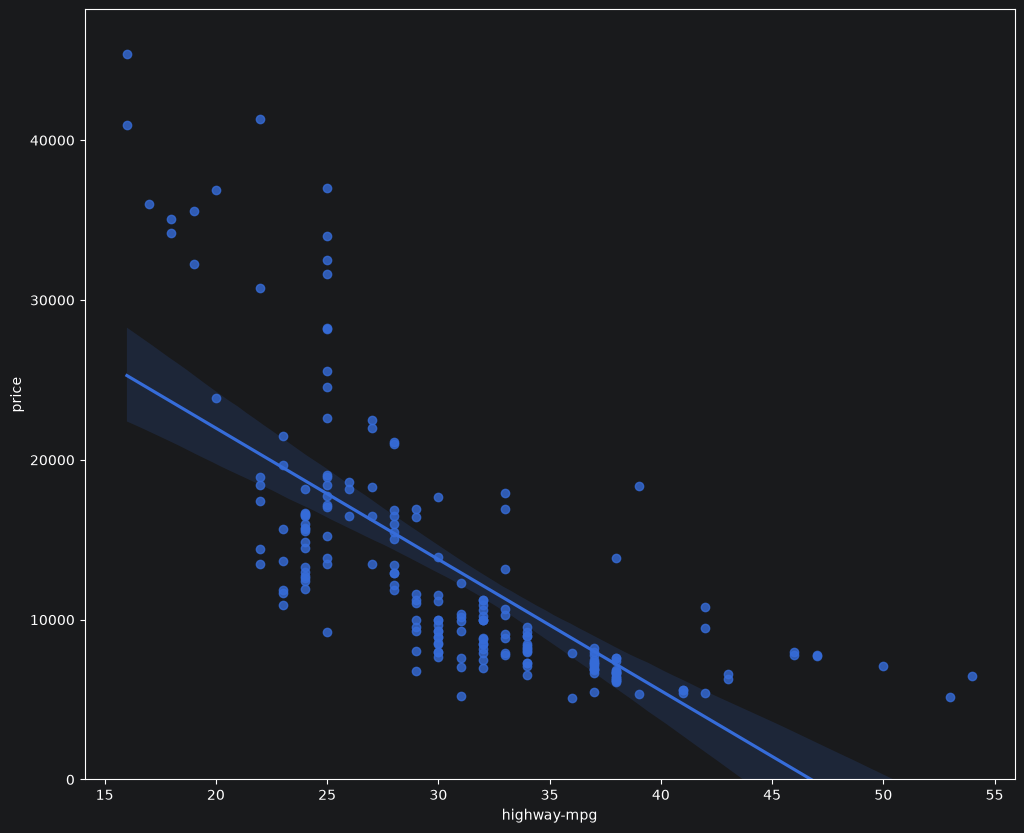

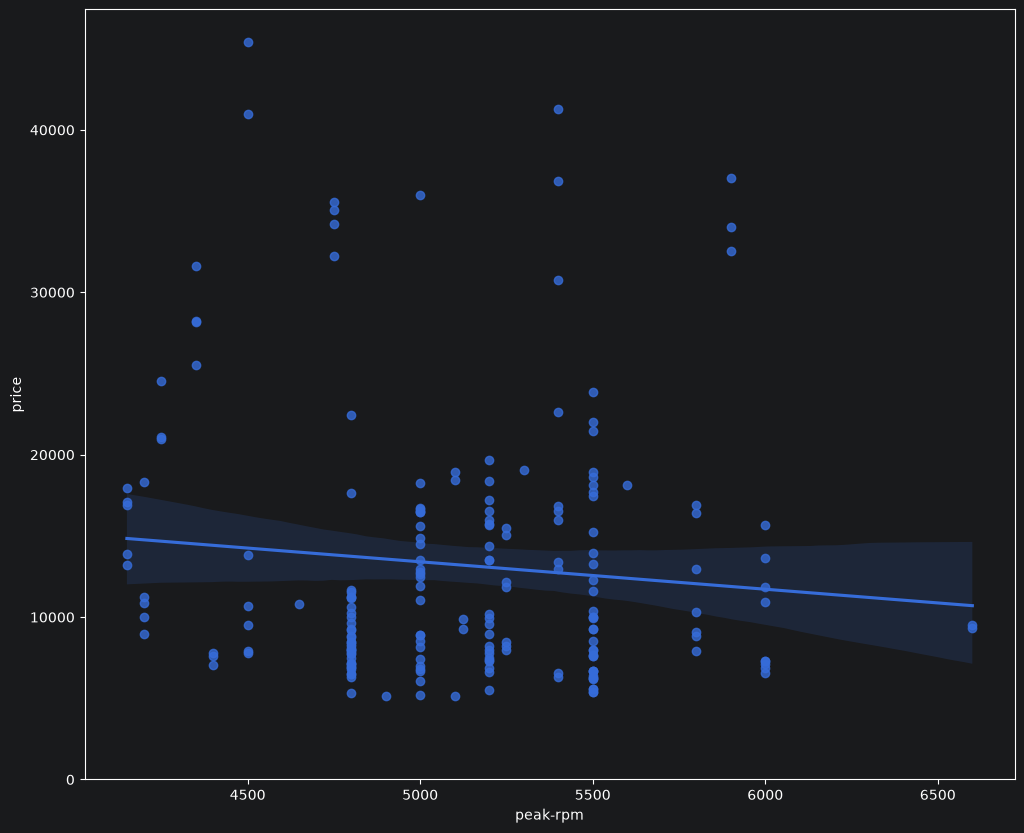

In [18]:
lm2 = LinearRegression()
lm2.fit(df[['normalized-losses' , 'highway-mpg']],df['price'])

lm2.coef_


# 确定画布大小 → 创建画布 → 散点+回归线+置信带 → Y轴从0开始
import seaborn as sns
%matplotlib inline

#定义画布的宽和高（单位是英寸）
#单独存成变量的好处：后面还有几张图，复用同一个尺寸，图片风格统一
width = 12
height = 10
# 用 matplotlib 创建一张 12×10 英寸的空白画布
# 必须在绘图语句之前调用，否则设置不生效
# 不设置的话默认约 6.4×4.8 英寸，对散点较多的图会显得拥挤
plt.figure(figsize=(width, height))

# sns 是开头 import seaborn 的别名，regplot = regression plot（回归图）
# 一次调用画出三层内容：
# 图层	内容
# 散点	df 中每辆车的 (highway-mpg, price)，201 个真实数据点
# 直线	对这些散点做线性拟合得到的回归线——就是 lm.fit(X, Y) 学到的那条回归线
# 阴影带	回归线周围的置信区间（默认 95%），带子越宽说明该区域预测越不确定
sns.regplot(x="highway-mpg", y="price", data=df)
# 把 Y 轴显示范围设为 从 0 开始（上限自动）
# 为什么要写？price 不可能是负数，但回归直线延伸到图形边缘时可能画出负值区域；从 0 开始更符合业务常识
plt.ylim(0,)
#这张图在 lab 里的作用？
# 散点是否紧贴直线：mpg 在 20~35 区间的点贴得较好；mpg < 20 的区域散点明显偏离（价格昂贵的车油耗高但价格分化大）
# 直线形状是否合理：可以看出价格随 mpg 上升而下降，但下降速度在变缓——这不是一条完美直线 → 为后面引入多项式回归埋下伏笔

plt.figure(figsize=(width, height))
sns.regplot(x="peak-rpm", y="price", data=df)
plt.ylim(0,)



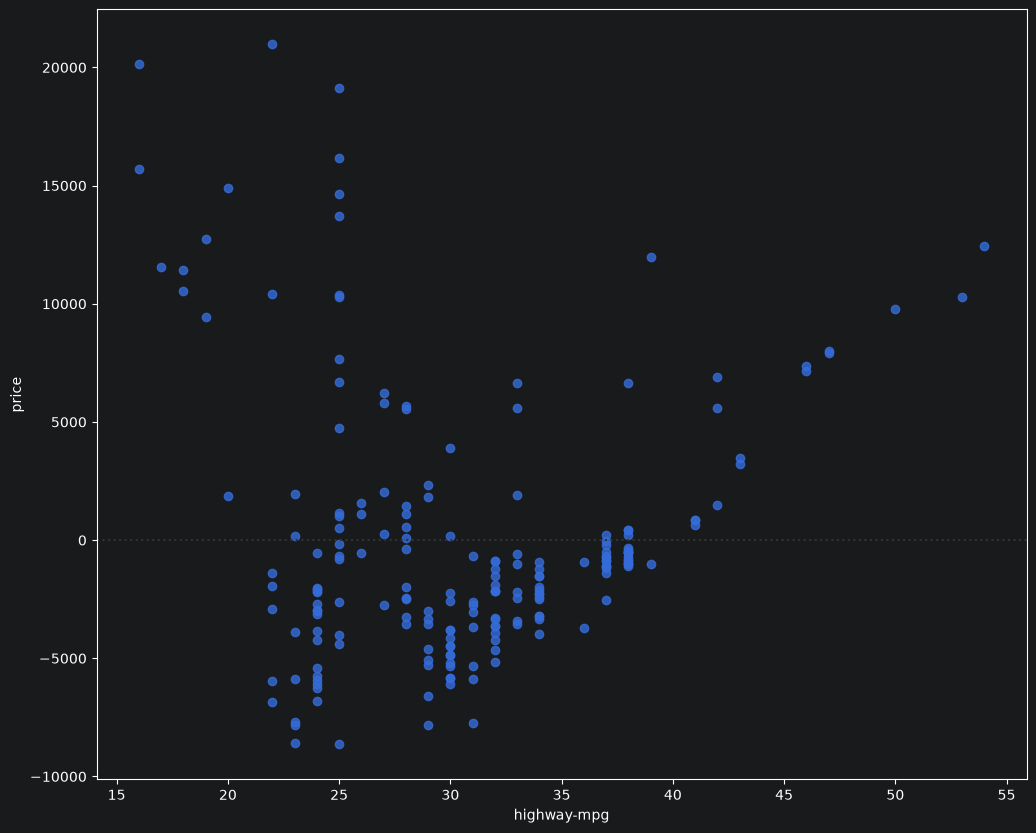

C:\Users\A\AppData\Local\Temp\ipykernel_6424\2756785331.py:41: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax1 = sns.distplot(df['price'], hist=False, color="r", label="Actual Value")
C:\Users\A\AppData\Local\Temp\ipykernel_6424\2756785331.py:51: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distp

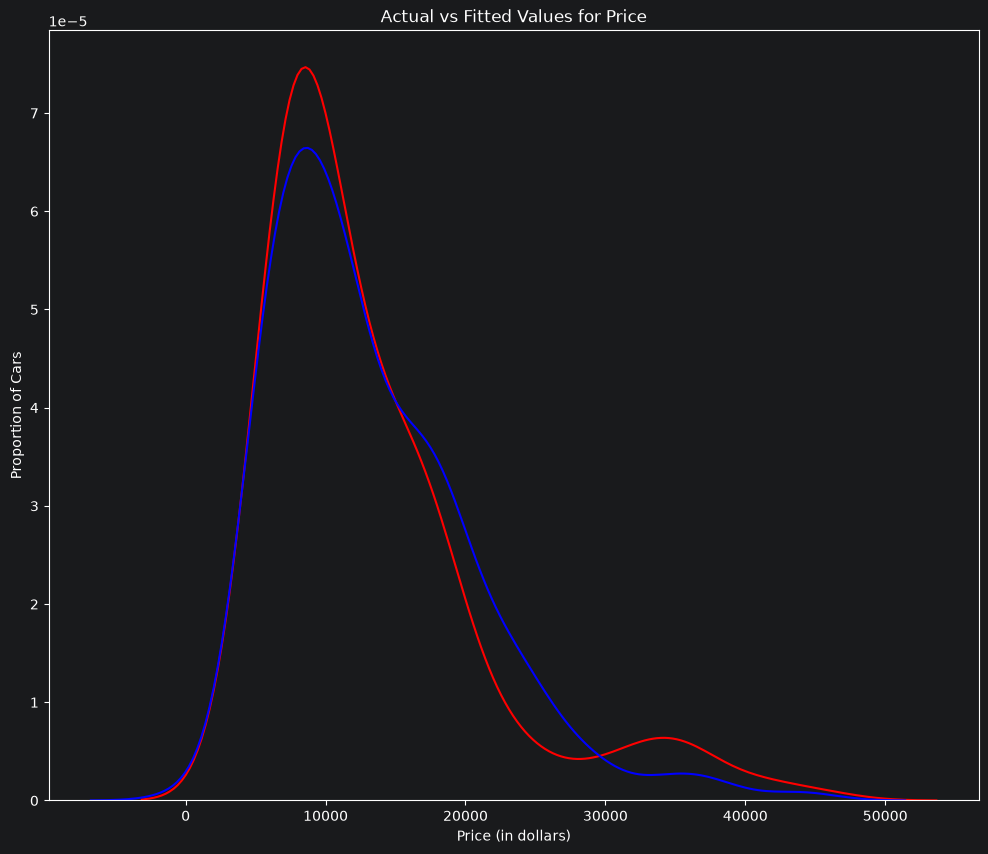

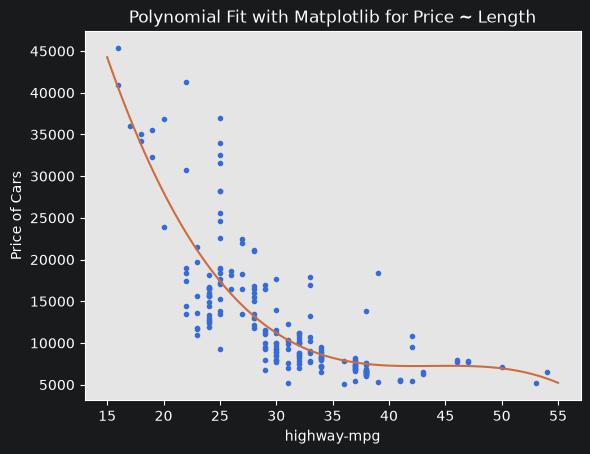

array([-1.55663829e+00,  2.04754306e+02, -8.96543312e+03,  1.37923594e+05])

In [19]:
df[["peak-rpm","highway-mpg","price"]].corr()

# regplot 画的是：散点 + 回归线（看“拟合长什么样”）
# residplot 画的是：每个点到回归线的垂直距离（看“拟合差多少”）
width = 12
height = 10
plt.figure(figsize=(width, height))
# 解析——残差图：检验线性模型是否合适
# 一行代码内部其实做了三件事：
# 对 (highway-mpg, price) 做线性拟合，得到Yhat
# 计算每个样本的残差 Y-Yhat
# 以 X 为横轴、残差为纵轴画散点图（图中横线 y=0就是那条"理想回归线”的位置）
# residual plot：自动完成 拟合→预测→算残差→画图 全流程
#自变量和因变量都是直接传 Series 列，和regplot不同
sns.residplot(x=df['highway-mpg'], y=df['price'])
plt.show()
# 残差图的形态	            结论
# 随机散布在 0 上下，无规律	线性模型合适，误差是随机噪音
# 呈现曲线趋势（U形/弧形）	数据有非线性关系，线性模型不合适
# 本 lab 的实际结果：残差图呈现明显的弯曲模式——低 mpg 区域残差为负（模型高估价格），中间区域为正，高 mpg 区域又变化。这说明价格和 highway-mpg 不是纯线性关系。
#这张图诊断出了简单线性回归不足，所以后面引入了多项式回归

# regplot	residplot
# 横轴	    highway-mpg	highway-mpg
# 纵轴	    price（原始值）	残差（误差值）
# 回归线	显示出来	隐含在 y=0 参考线
# 回答的问题    拟合长什么样？	拟合得好不好？


#根据拟合好的公式进行预测（多项）
Y_hat = lm.predict(Z)
plt.figure(figsize=(width, height))

# 参数	                           含义
# sns.distplot	            seaborn 的分布图函数，这里只画曲线不画柱子（该函数在新版 seaborn 中已弃用，替代方案见文末）
# df['price']	            数据来源：201 辆车的真实价格列
# hist=False	            不画直方图，只画平滑的概率密度曲线（KDE）
# color="r"	                 曲线颜色为红色（red）
# label="Actual Value"	    图例标签为 "Actual Value"（真实值）
# ax1 = ...	                把返回的坐标轴对象存到 ax1，供下一行在其上叠加第二条曲线
ax1 = sns.distplot(df['price'], hist=False, color="r", label="Actual Value")

# 这行是上一行的“配对”代码——把模型预测价格画成蓝色曲线，叠加到真实价格的图上。
# 参数	含义
# Y_hat	上一节             lm.predict(Z) 的结果：模型对 201 辆车的预测价格数组（多元线性回归，4 个特征）
# hist=False	        不画直方图，只画平滑的核密度估计曲线（KDE）——可以理解为一条“概率密度曲线”，反映各价格附近的车有多密集
# color="b"	            曲线颜色为蓝色（blue），与上一行的红色真实值形成对比
# label="Fitted Values"	图例标签 "Fitted Values"（拟合值/预测值），与上一行的 "Actual Value" 对应
# ax=ax1	            最关键的参数：指定画到 ax1 这个坐标系上
# 这实现了叠加绘图——红蓝两条曲线共享同一坐标系，才能直接对比
sns.distplot(Y_hat, hist=False, color="b", label="Fitted Values" , ax=ax1)


# 语句	画的内容	数据来源	颜色
# 第一句	真实价格的分布曲线	df['price']（数据集里每辆车实际的售价）	🔴 红
# 第二句	预测价格的分布曲线	Y_hat（模型 lm.predict(Z) 算出来的价格）🔵 蓝

#等价写法
# ax1 = sns.kdeplot(df['price'], color="r", label="Actual Value")
# sns.kdeplot(Y_hat, color="b", label="Fitted Values", ax=ax1)

#设置图标题，x轴标签"价格（美元）"，y轴标签"车辆占比"，因为用的是 KDE 密度曲线（hist=False），纵轴表示的不是车的数量，而是该价格附近的车有多密集——曲线越高，说明这个价位的车越常见。
plt.title('Actual vs Fitted Values for Price')
plt.xlabel('Price (in dollars)')
plt.ylabel('Proportion of Cars')

plt.show()
# 关闭当前图形窗口，释放画布。
plt.close()

# 总结
# 图类型	使用的 seaborn 函数	适用模型	出现位置
# 回归图	sns.regplot()	只有简单线性回归（1 个自变量）	评估 highway-mpg 单变量模型
# 残差图	sns.residplot()	只有简单线性回归	检验线性假设是否成立
# 分布图	sns.distplot()	多元线性回归、其他模型	就是这段代码


# 参数	含义	实际调用时传入的值
# model	已拟合好的多项式函数（如 np.poly1d 对象 p）	三次多项式模型
# independent_variable	自变量（原始数据点）	df['highway-mpg']
# dependent_variabble	因变量（原始数据点，注意源码里这个拼写就是错的，只是参数名不影响运行）	df['price']
# Name	x 轴标签文字	'highway-mpg'
def PlotPolly(model, independent_variable, dependent_variabble, Name):
    # 生成 100 个等间距的 x 值，范围从 15 到 55（覆盖 highway-mpg 的取值区间）。作用是生成一条平滑曲线的“骨架”——如果只用原始的 201 个散点连线，曲线会锯齿状不光滑。
    x_new = np.linspace(15, 55, 100)

    # 把多项式模型套用到这 100 个新 x 值上，算出对应的 y 值。p 是 np.poly1d 对象，可以像函数一样直接调用：p(30) 就等于把 mpg=30 代入三次多项式算价格。得到 100 个 (x, y) 点，连起来就是拟合曲线。
    y_new = model(x_new)

    # 这是本函数的核心——一次 plt.plot 同时画两组数据：
    # 数据	样式	含义
    # independent_variable, dependent_variabble	'.'	🔵 散点：201 辆车的真实数据（mpg, price）
    # x_new, y_new	'-'	                            📈 实线：多项式拟合曲线
    # 这样能直观看出曲线“穿过”了多少数据点——贴得越紧，拟合越好。
    plt.plot(independent_variable, dependent_variabble, '.', x_new, y_new, '-')
    plt.title('Polynomial Fit with Matplotlib for Price ~ Length')
    # gca = Get Current Axes，获取当前坐标轴对象，为下一行修改背景色做准备。
    ax = plt.gca()
    # 把绘图区背景设为浅灰色。RGB 三通道都是 0.898（约 229/255），纯装饰，让图更好看。
    ax.set_facecolor((0.898, 0.898, 0.898))
    # gcf = Get Current Figure，获取当前画布对象。这里只是赋值保存、后面没用它，属于可有可无的一行。
    fig = plt.gcf()
    # 设置轴标签：x 轴是传入的变量名（highway-mpg），y 轴是“车价”。
    plt.xlabel(Name)
    plt.ylabel('Price of Cars')

    # 显示图像并关闭画布——和上一节分布图的作用一样。
    plt.show()
    plt.close()


x = df['highway-mpg']
y = df['price']

# 之前简单线性回归拟合这条数据效果不好（R² 仅 0.497，残差图也不随机），所以改用三次多项式：
# np.polyfit(x, y, 3)：用最小二乘法拟合一个 3 次多项式
# 返回值 f 是一个系数数组，从最高次到常数项排列：[b₃, b₂, b₁, a]
# 实际输出类似：array([ 1.8794e-07, -1.0450e-03, 1.4694e+00, 1.4694e+02])
#相当于先把系数算出来
f = np.polyfit(x, y, 3)

# np.poly1d(f)：把系数数组 f 包装成一个多项式对象
# 这个对象可以像函数一样直接调用：
# p(30) → 把 mpg=30 代入多项式，返回预测车价
# 甚至支持向量输入：p(np.array([20, 30, 40])) → 返回 3 个预测价
# 它还能参与运算，比如 p - q（多项式相减）、求导 p.deriv()
# 没有这一步，你手里只有一串系数，还得手写 b3*x**3 + b2*x**2 + b1*x + a；有了它，直接 p(x) 就行。这也是为什么后面的 PlotPolly 里能写 y_new = model(x_new)——model 就是这个 p。
#这就是个公式，能把系数都填进去，形成多项式对象
p = np.poly1d(f)

PlotPolly(p, x, y, 'highway-mpg')
# 把系数数组直接显示出来
np.polyfit(x, y, 3)

# 这个函数plotpolly，其实就是对比真实价格和预测价格的，只不过这次预测价格采用的是三次多项式
#           分布图（MLR 那张）	    PlotPolly（多项式这张）
# 模型	多元线性回归（4 个特征）	三次多项式（1 个特征：highway-mpg）
# 真实值	红色密度曲线 df['price']	蓝色散点 '.'（每个点 = 一辆车的真实 mpg 和真实价格）
# 预测值	蓝色密度曲线 Y_hat	平滑拟合曲线 '-'（p(x_new) 算出的预测价格）
# 呈现方式	看两条分布是否重叠	看曲线穿过多少个散点

# 这两个可视化干的都是同一件事——“真实价格 vs 模型预测价格”的对比评估。区别只在于：
# 多元线性回归 → 只能看分布贴不贴合
# 三次多项式（单变量）→ 可以直接看曲线贴不贴合散点，更直观

            11             10             9           8         7
-1.243e-08 x  + 4.722e-06 x  - 0.0008028 x + 0.08056 x - 5.297 x
          6        5             4             3             2
 + 239.5 x - 7588 x + 1.684e+05 x - 2.565e+06 x + 2.551e+07 x - 1.491e+08 x + 3.879e+08


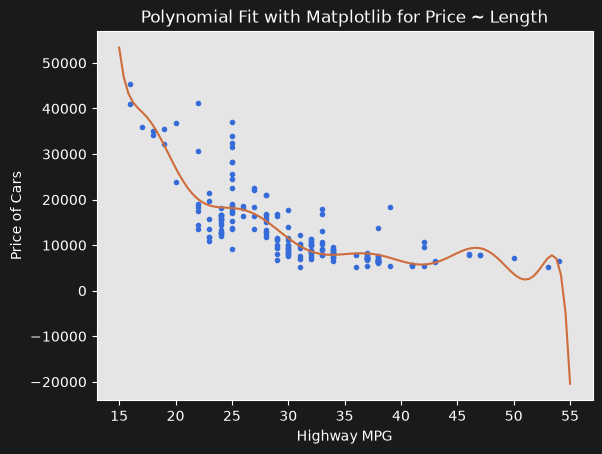

array([13102.74784201, 13102.74784201, 18225.54572197, 10390.29636555])

In [20]:

# x = df['highway-mpg']
# y = df['price']
f1 = np.polyfit(x, y, 11)
p1 = np.poly1d(f1)
print(p1)
PlotPolly(p1,x,y, 'Highway MPG')


# 从 scikit-learn 的数据预处理模块 sklearn.preprocessing 中导入 PolynomialFeatures 类。
from sklearn.preprocessing import PolynomialFeatures


# 从 sklearn.preprocessing 实例化一个多项式特征生成器，degree=2 表示生成最高 2 次的多项式组合。
# 此处只是创建对象，还没有真正处理数据（惰性构建，需要后续 fit / fit_transform 才会计算）。
pr=PolynomialFeatures(degree=2)  #标准化
pr

# fit_transform(Z) — 实际上是两个动作的组合：
# fit(Z)：扫描 Z，统计每个特征的取值范围、组合方式，确定要生成哪些多项式项（哪些一次项、平方项、交叉项）。
# transform(Z)：按拟合好的规则实际计算并输出新特征矩阵。
# 两者合并写成 fit_transform 是 sklearn Transformer 的标准接口习惯（一次性完成“学习规则 + 应用规则”）。
Z_pr=pr.fit_transform(Z)

# 对 4 个特征做 2 阶展开（include_bias=True 默认）：
# 1 个截距列（全 1）
# 4 个一次项
# 4 个平方项 horsepower 的平方  curb-weight 的平方 engine-size 的平方 highway-mpg 的平方
# 6 个交叉项 horsepower × curb-weight  horsepower × engine-size .....
#也就是使用了fit_transform这个方法，能够对原来的四个列进行升维，新增11列
# 它们对应升维后矩阵中的 4 个一次项列——这 4 列是“原有的”。升维后变成 15 列，新增的 11 列就是：1 个截距列 + 4 个平方项 + 6 个交叉项。
#特征指数 powers_ 记录的是 Z_pr 每一列的“指数配方”
# powers_ =（powers_ 是"列清单"的转置视图——每行是一个列的配方，所以 11 个新增列在）
# [[0 0 0 0]   ①  1（截距列，全1）          [新增]
#  [1 0 0 0]   ②  x1 = horsepower          （原有）
#  [0 1 0 0]   ③  x2 = curb-weight         （原有）
#  [0 0 1 0]   ④  x3 = engine-size         （原有）
#  [0 0 0 1]   ⑤  x4 = highway-mpg         （原有）
#  [2 0 0 0]   ⑥  x1² = horsepower²        [新增]
#  [1 1 0 0]   ⑦  x1·x2                    [新增]
#  [1 0 1 0]   ⑧  x1·x3                    [新增]
#  [1 0 0 1]   ⑨  x1·x4                    [新增]
#  [0 2 0 0]   ⑩  x2²                      [新增]
#  [0 1 1 0]   ⑪  x2·x3                    [新增]
#  [0 1 0 1]   ⑫  x2·x4                    [新增]
#  [0 0 2 0]   ⑬  x3²                      [新增]
#  [0 0 1 1]   ⑭  x3·x4                    [新增]
#  [0 0 0 2]]  ⑮  x4²                      [新增]



# Z = df[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']]
# .shape 是 pandas DataFrame 的属性（不是函数，所以不带括号），返回一个元组 (行数, 列数)，即 (样本数, 特征数)。
# (201, 4)
# 201：数据集中有效样本数（去掉含缺失值的价格等行之后）；
# 4：horsepower、curb-weight、engine-size、highway-mpg 这 4 个自变量。
Z.shape

# 和上面的进行对比
# PolynomialFeatures(degree=2) 把特征列从 4 列扩到了 15 列，而样本数保持 201 不变。如果忘记对比，容易在后面 lm.fit(Z_pr, y) 时误以为维数变化正常或数据出错。
Z_pr.shape

# 1	x0	x1	x2	x3	x0²	x0·x1	x0·x2	x0·x3	x1²	x1·x2	x1·x3	x2²	x2·x3	x3²
# 1	111	2548	130	27	12321	282828	14430	2997	6492304	331240	68796	16900	3510	729
# 1	111	2548	130	27	12321	282828	14430	2997	6492304	331240	68796	16900	3510	729
# 1	154	2823	152	26	23716	434742	23408	4004	7969329	429096	73398	23104	3952	676
# 例如第 7 列 x0·x1（horsepower × curb-weight）


# Pipeline 是 scikit-learn 的工作流编排工具，作用是把多个数据处理和建模步骤按顺序串成一条链，对外表现得像一个模型。
from sklearn.pipeline import Pipeline
# StandardScaler 是标准化器，把每个特征变换为均值 0、标准差 1
from sklearn.preprocessing import StandardScaler
# 两个导入对应的就是这条流水线中“数据预处理”环节的两个角色：一个负责统一量纲（StandardScaler），一个负责按序编排（Pipeline）。

# 这是为下一步创建 Pipeline 准备的步骤清单——一个由 3 个 (名称, 对象) 元组组成的 Python 列表，每个元组代表流水线中的一站。
# ① ('scale', StandardScaler()) — 第一站：标准化 把每个特征变换为均值 0、标准差 1
#必须放在最前面，原因你在 Z_pr 的输出里已经见过：原始 4 列量级悬殊（highway-mpg 只有二三十，curb-weight 几千），若先升维，数值不稳定，所以我们要先标准化，再升维
# ② ('polynomial', PolynomialFeatures(include_bias=False)) — 第二站：多项式升维（这里没有指定 degree，默认 degree=2，效果与之前 pr = PolynomialFeatures(degree=2) 相同（4 列 → 14 列）。）
# 关键区别：include_bias=False。之前单独用时默认含偏置（15 列，多一列全 1）；这里去掉它，因为第三站的 LinearRegression 自带截距项，不需要数据里再提供一列 1——避免冗余。我们给数据人为加一列“恒等于 1 的特征”；全 1 列只是一个取值恒为 1 的“假特征”，为了体现b0*1这一项
# ③ ('model', LinearRegression()) — 第三站（终点）：线性回归 升维后的 14 列特征交给线性回归拟合，整体上等效于多项式回归：
Input=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(include_bias=False)), ('model',LinearRegression())]
# 前面的做法（第 16–23 行）	本行的 Pipeline 做法
# 流程	    手动 fit_transform → 手动 lm.fit	一条链自动完成
# 偏置列	有（15 列，含冗余全 1 列）	无（14 列，include_bias=False）
# 标准化	没有（升维后数值巨大）	有（先缩放再升维）
# 预测一致性	需手动重复每个预处理步骤	自动保证

# 此处只是组装，还没有训练——三个子对象仍然是未拟合状态，pipe 此刻只是一个“执行计划”。
pipe=Pipeline(Input)
pipe #Pipeline(steps=[('scale', StandardScaler()), ('polynomial', PolynomialFeatures(include_bias=False)),('model', LinearRegression())])

# 数据清洗 把 Z（horsepower、curb-weight、engine-size、highway-mpg 4 列）的 dtype 统一转成 float64。
# 为什么需要这一步？ 因为 usedcars.csv 原始数据里部分数值列是以字符串（object）类型读入的（历史原因：该数据集的 horsepower、normalized-losses 等列含 ? 缺失标记，被 pandas 当作 object 处理；或从其他 notebook 传递过来时保留了 object 类型）。
Z = Z.astype(float)
# pipe.fit(Z, y) — 流水线训练 一行代码触发整条链，内部按 Input 定义的顺序自动执行三步：
# pipe.fit(Z, y)
#    ├─ ① StandardScaler.fit(Z) / .transform(Z)
#    │      学习每个特征的 μ 和 σ，把 Z 变成均值0、标准差1 → (201, 4)
#    ├─ ② PolynomialFeatures.fit / .transform
#    │      对标准化后的数据做 2 阶展开（include_bias=False）→ (201, 14)
#    └─ ③ LinearRegression.fit(升维后的特征, y)
#           用最小二乘法求出 β，训练完成
pipe.fit(Z,y)

# 用算出来的式子开始预测价格
ypipe=pipe.predict(Z)
ypipe[0:4]
# ypipe[0:4] 就是模型对前 4 辆车预测价格的浮点数组，前两项因车辆配置相同而相等；用它对照 y[0:4] 的真实价格，可以直观感受模型预测与实际值之间的差距



# 总结一下：手动挡与自动档（到fit计算系数之前，全自动化，标准化，升维，传递模型，用最小二乘法拟合一个线性模型，在 Lab01 里，它是所有模型（简单线性、多元线性、多项式回归）的核心引擎。）
# 手动
# 第1步：自己算标准化
# scaler = StandardScaler()
# Z_scaled = scaler.fit_transform(Z)     # 自己拿中间结果

# # 第2步：自己传给升维器
# poly = PolynomialFeatures(degree=2, include_bias=False)
# Z_poly = poly.fit_transform(Z_scaled)  # 又自己拿一次

# # 第3步：自己传给模型
# lm = LinearRegression()
# lm.fit(Z_poly, y)                      # 自己又拿一次

# # 预测时：必须手动重复整条链！
# Z_new_scaled = scaler.transform(Z_new)     # 忘一步就出错
# Z_new_poly = poly.transform(Z_new_scaled)
# y_pred = lm.predict(Z_new_poly)

# 自动
# pipe = Pipeline(Input)
# pipe.fit(Z, y)                # 训练：内部自动串联三步
# y_pred = pipe.predict(Z_new)  # 预测：内部自动重复整条链



The R-square is:  0.4965911884339176
The output of the first four predicted value is:  [16236.50464347 16236.50464347 17058.23802179 13771.3045085 ]
The mean square error of price and predicted value is:  31635042.944639888
The R-square is:  0.8093562806577457
The mean square error of price and predicted value using multifit is:  11980366.87072649
The R-square value is:  0.674194666390652
[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]
 [18]
 [19]
 [20]
 [21]
 [22]
 [23]
 [24]
 [25]
 [26]
 [27]
 [28]
 [29]
 [30]
 [31]
 [32]
 [33]
 [34]
 [35]
 [36]
 [37]
 [38]
 [39]
 [40]
 [41]
 [42]
 [43]
 [44]
 [45]
 [46]
 [47]
 [48]
 [49]
 [50]
 [51]
 [52]
 [53]
 [54]
 [55]
 [56]
 [57]
 [58]
 [59]
 [60]
 [61]
 [62]
 [63]
 [64]
 [65]
 [66]
 [67]
 [68]
 [69]
 [70]
 [71]
 [72]
 [73]
 [74]
 [75]
 [76]
 [77]
 [78]
 [79]
 [80]
 [81]
 [82]
 [83]
 [84]
 [85]
 [86]
 [87]
 [88]
 [89]
 [90]
 [91]
 [92]
 [93]
 [94]
 [95]
 [96]
 [97]
 [98]
 [99]]


D:\pythonCourse\pythonCode\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


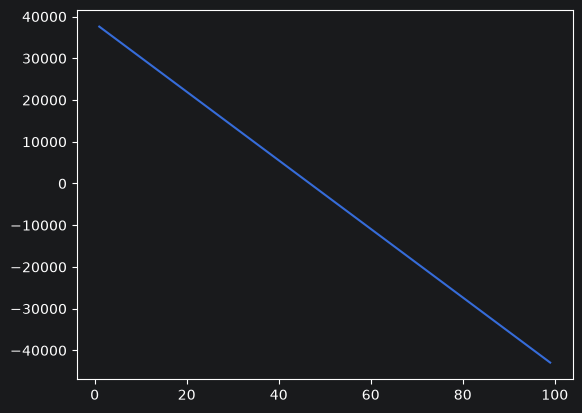

In [21]:
Input=[('scale',StandardScaler()),('model',LinearRegression())]

pipe=Pipeline(Input)

pipe.fit(Z,y)

ypipe=pipe.predict(Z)
ypipe[0:10]

# 对前面创建的 lm = LinearRegression() 执行最小二乘拟合：在“highway-mpg vs price”散点上找一条直线，使所有样本的残差平方和最小

#这里的 X = df[['highway-mpg']]、Y = df['price']——即用“高速油耗里程”单变量预测价格，训练，训练完成后，模型内部产生两个参数
lm.fit(X, Y)
# score 是 sklearn 估计器的通用评估接口，对回归模型默认返回 R²（决定系数）
# 直观理解：价格波动中有多大的比例能被 highway-mpg 解释。
# 解读：约 49.66%——一半左右的价格差异能用油耗解释，一半解释不了（受品牌、发动机、车况等影响）。作为单变量模型，这个 R² 只算一般，说明 SLR 能力有限。
print('The R-square is: ', lm.score(X, Y))
# 这一单元是三种模型的第一个基准点。后续会依次对比：
# 模型	特征	R²（约）
# SLR（本单元）	highway-mpg	0.497
# MLR	4 个特征	0.809
# 多项式（Pipeline）	4 特征 2 阶升维	更高
# R² 逐级上升，配合 MSE 和分布图/残差图，最终支撑“多项式回归拟合效果最好”的选型结论。

# R² 是判定“模型是否合适”的必要参考，但不是充分判据：它回答“解释了多少方差”（量的问题）；“假设对不对”（形态）要靠残差图，“会不会过拟合”（泛化）要靠 MSE 对照/独立测试数据。单看 R² 定模型 = 只看分数不看错题——把它和 MSE、残差图、分布图组合使用，才是 Lab01 教给你的完整评估方法

# predict 把训练学到的公式应用到全部 201 个样本上 批量预测
Yhat=lm.predict(X)
print('The output of the first four predicted value is: ', Yhat[0:4])

# 从 sklearn.metrics（度量指标模块）导入均方误差函数 mean_squared_error。
from sklearn.metrics import mean_squared_error
# 对每个样本算“预测值 − 真实值”，平方后取平均。（这就是MSE）
# MSE 越小越好——MLR 的 MSE 比 SLR 小了一半以上，验证了 R² 上升的结论。
mse = mean_squared_error(df['price'], Yhat)
print('The mean square error of price and predicted value is: ', mse)
# 为什么有了 R² 还要 MSE
# 这两个指标互补，缺一不可：
# ① 单位与量纲不同
# R² 无量纲（0~1 的比例），适合跨模型横向比较；
# MSE 带价格的平方单位（美元²），数字巨大（10⁷ 量级），但对误差的绝对大小更敏感直观。
# ② 防止单一指标误导
# 只看 R²：加无用变量 R² 也会涨（过拟合风险被掩盖）；
# 只看 MSE：不同数据集之间没法比（量纲依赖数据本身）；
# 教材的结论方式就是“R² + MSE 组合判定”：如 "The MSE of SLR is 3.16×10⁷ while MLR has 1.2×10⁷. The MSE of MLR is much smaller." ——两个指标同向，选型结论才可靠。
# ③ 平方的含义平方有两个作用：① 消除正负误差相互抵消（预测偏高和偏低都算“错”）；② 放大大误差的惩罚——差 5000 的样本比差 1000 的样本“恶劣” 25 倍，模型会优先照顾错得离谱的预测。

lm.fit(Z, df['price'])
print('The R-square is: ', lm.score(Z, df['price']))

Y_predict_multifit = lm.predict(Z)
print('The mean square error of price and predicted value using multifit is: ', \
      mean_squared_error(df['price'], Y_predict_multifit))


# 从 sklearn.metrics 导入 R² 打分函数，和上一行的 mean_squared_error 是同一个模块的邻居——评估指标全家桶里的两个成员。
from sklearn.metrics import r2_score
# x = df['highway-mpg']              # 自变量：高速油耗里程（201 个值）
# y = df['price']                    # 因变量：真实价格（201 个值）
# f = np.polyfit(x, y, 3)            # 用 3 次多项式拟合，返回 4 个系数
# p = np.poly1d(f)                   # 打包成"多项式函数"对象 p
# y 是什么
# 真实价格数组，来自数据集 price 列，形状 (201,)。
# 在 r2_score(y, p(x)) 中充当基准答案（y_true）——模型要预测的对象。
# p(x) 是什么
# p 是 np.poly1d 打包出来的3 次多项式函数

# p(x) 表示把全部 201 个 highway-mpg 值代入这个多项式，得到 201 个预测价格——即模型的预测值数组
# 先用 p(x) 算出 201 个预测价格；
# 再把“真实 vs 预测”交给 r2_score，算出这个 3 次多项式模型解释了多少价格方差；
# 结果存入 r_squared，第 59 行打印，输出约为 0.6744。
r_squared = r2_score(y, p(x))
print('The R-square value is: ', r_squared)

# 为什么必须用 r2_score 而不是 .score()
# 呼应你上一个问题：p 是 np.poly1d 对象，不是 sklearn 估计器，没有 .score() 方法。所以只能：
# 自己先算预测值 p(x)；
# 再调用独立函数 r2_score(y, 预测值) 打分。
# 核心原因：模型对象是谁家的，决定了能用哪种方式
# 一句话版：lm.score() 是“模型自带的打分器”，只有 sklearn 家的模型才有；p 是 NumPy 家的多项式，它没有这个方法，只能用独立的 r2_score 函数“从外面”给它打分。
# 前面（SLR/MLR/PIPELINE）：sklearn 估计器
# lm = LinearRegression()      # sklearn 家的模型
# sklearn 规定：所有估计器都必须实现统一的接口——fit / predict / score。所以 lm 天生自带 score 方法，且内部会自动帮你调 predict：
# 这里（多项式）：NumPy 的对象
# f = np.polyfit(x, y, 3)   # 返回系数数组
# p = np.poly1d(f)          # NumPy 家的多项式函数
# p 只是一个“会算多项式值的数学对象”，不存在 fit/predict/score 这套接口。你写 p.score(...) 会直接报错

# p(x)相当于yhat
mean_squared_error(df['price'], p(x))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline


# 生成从 1 开始、到 99 结束（不含 100）、步长为 1 的等差数组
# 结果是一个一维数组：[1, 2, 3, ..., 99]，共 99 个元素
# 把一维数组重塑成二维列向量，-1 表示行数自动推算，1 表示每行 1 个特征
# 为什么要 reshape？
# 这是 scikit-learn 的硬性要求：lm.predict() 期望输入是 二维结构 (n_samples, n_features)。如果直接传一维数组，会报经典错误
# reshape把一维数组变成一列99行
new_input=np.arange(1, 100, 1).reshape(-1, 1)

print(new_input)
# 拟合
lm.fit(X, Y)
lm

# 预测价格
yhat=lm.predict(new_input)
yhat[0:5]

# 画出预测线
plt.plot(new_input, yhat)
plt.show()


